<a href="https://colab.research.google.com/github/amicable594-beep/garbage-classification/blob/main/garbage_classification_final_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 제1회 빅데이터 프로그래밍 해커톤

# CNN을 활용한 쓰레기 이미지 분류

## 1. 프로젝트 개요

### 1.1 프로젝트 주제

본 프로젝트는 딥러닝의 합성곱 신경망(CNN, Convolutional Neural Network)을 활용하여 쓰레기 이미지를 자동으로 분류하는 모델을 구현하는 것을 목적으로 한다.

### 1.2 프로젝트 목적

일상생활에서 발생하는 쓰레기는 재질과 종류에 따라 분리배출 방법이 다르다. 하지만 종류가 다양하고 외형이 유사한 쓰레기가 존재하기 때문에 정확한 분류가 어려울 수 있다.

이에 따라 이미지 데이터를 학습한 CNN 모델을 이용하여 쓰레기 이미지를 자동으로 분류하고, 모델의 정확도와 분류 성능을 평가하고자 한다.

### 1.3 사용 데이터셋

- 데이터셋: Garbage Classification (12 classes)
- 출처: Kaggle
- 제공자: Mostafa Mohamed
- 데이터 주소: https://www.kaggle.com/datasets/mostafaabla/garbage-classification

### 1.4 분류 대상

본 프로젝트에서는 다음 12개 종류의 쓰레기를 분류한다.

1. Battery
2. Biological
3. Brown-glass
4. Cardboard
5. Clothes
6. Green-glass
7. Metal
8. Paper
9. Plastic
10. Shoes
11. Trash
12. White-glass

### 1.5 개발 방향

PyTorch를 활용하여 CNN 모델을 직접 구현한다.

학습 과정에서 데이터 증강, 과적합 분석 및 하이퍼파라미터 튜닝을 진행하고, 혼동행렬을 통해 클래스별 분류 성능을 평가한다.



### 생성형 AI 활용 기록 1

**활용 도구:** ChatGPT

**사용 목적:** CNN 모델의 개념 이해 및 프로젝트 구현 방향 설정

**실제 입력 프롬프트:**
- "cnn모델이 뭐야"
- "그걸 파이선으로 만들 수 있어?"
- "과적합은 뭐야?"
- "너가 만들어준 cnn모델의 적합도는 좋은편이야?"

**활용 내용:**

CNN의 기본 개념과 이미지 분류에서의 역할을 이해하고, PyTorch를 활용한 직접적인 모델 구현 방향을 설정하는 데 활용하였다.

In [3]:

# 필요한 라이브러리 불러오기

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# GPU 사용 여부 확인
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())
print("현재 사용 장치:", device)

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))


PyTorch 버전: 2.14.1+cu130
GPU 사용 가능: True
현재 사용 장치: cuda
GPU 이름: Tesla T4



### 2. 개발 환경 및 라이브러리

본 프로젝트는 Google Colab 환경에서 진행하였으며, 딥러닝 모델 구현을 위해 PyTorch를 사용하였다.

이미지 처리에는 PIL과 torchvision을 활용하였고, 데이터 분할 및 분류 성능 평가에는 Scikit-learn을 사용하였다.

모델 학습에는 GPU 가속을 활용하여 연산 효율성을 높이고자 하였다.


## 3. 데이터 수집 및 탐색

### 3.1 데이터셋 다운로드

Kaggle에서 제공하는 Garbage Classification 데이터셋을 사용하였다.

Kaggle API를 이용하여 데이터를 Google Colab 환경으로 다운로드하고, 압축을 해제하여 이미지 분류에 활용하였다.

In [4]:

!pip install -q kaggle


In [5]:

from google.colab import files

uploaded = files.upload()

import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod(
    "/root/.kaggle/kaggle.json",
    0o600
)

print("Kaggle 인증 파일 설정 완료")


Saving kaggle.json to kaggle.json
Kaggle 인증 파일 설정 완료


In [6]:

# 데이터 저장 경로 설정
DATA_ROOT = "/content/garbage_data"

os.makedirs(DATA_ROOT, exist_ok=True)

# Kaggle 데이터셋 다운로드
!kaggle datasets download -d mostafaabla/garbage-classification -p /content/garbage_data

# 압축 해제
!unzip -q -o /content/garbage_data/garbage-classification.zip -d /content/garbage_data

print("데이터셋 다운로드 및 압축 해제 완료")


Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
100% 239M/239M [00:02<00:00, 101MB/s]

데이터셋 다운로드 및 압축 해제 완료



### 3.2 데이터셋 구성 확인

다운로드한 데이터셋의 폴더 구조와 클래스별 이미지 수를 확인한다.

이를 통해 데이터가 정상적으로 수집되었는지 확인하고, 이후 학습에 사용할 이미지 경로와 라벨을 구성한다.

In [7]:

# 12개 클래스 정의

CLASS_NAMES = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

# 실제 클래스 폴더 위치 찾기
class_root = None

for root, dirs, files in os.walk(DATA_ROOT):
    if all(name in dirs for name in CLASS_NAMES):
        class_root = root
        break

if class_root is None:
    raise FileNotFoundError(
        "12개 클래스 폴더를 찾을 수 없습니다."
    )

print("이미지 폴더 위치:", class_root)

# 클래스별 이미지 개수 확인
class_counts = {}

for class_name in CLASS_NAMES:
    folder = os.path.join(class_root, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    class_counts[class_name] = len(image_files)

# 표로 출력
count_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
})

display(count_df)

print("전체 이미지 수:", sum(class_counts.values()))


이미지 폴더 위치: /content/garbage_data/garbage_classification


,Class,Image Count
0,battery,945
1,biological,985
2,brown-glass,607
3,cardboard,891
4,clothes,5325
5,green-glass,629
6,metal,769
7,paper,1050
8,plastic,865
9,shoes,1977


전체 이미지 수: 15515


## 4. 데이터 전처리 및 데이터 분할

전체 이미지 데이터 15,515장을 학습 데이터, 검증 데이터, 테스트 데이터로 분할하였다.

- 학습 데이터(Train): 70%
- 검증 데이터(Validation): 15%
- 테스트 데이터(Test): 15%

데이터 분할 과정에서는 층화 추출(Stratified Sampling)을 적용하였다. 이를 통해 각 데이터에 포함된 클래스의 비율이 전체 데이터의 클래스 비율과 유사하게 유지되도록 하였다.

학습 데이터는 CNN 모델의 가중치를 학습하는 데 사용하고, 검증 데이터는 학습 과정에서 모델의 성능을 확인하는 데 사용한다. 테스트 데이터는 최종 모델의 성능을 평가하는 데 사용한다.

In [8]:
# 이미지 경로와 정답 레이블 수집
image_paths = []
image_labels = []

for label, class_name in enumerate(CLASS_NAMES):
    folder = os.path.join(class_root, class_name)

    for file_name in os.listdir(folder):
        if file_name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        ):
            image_paths.append(os.path.join(folder, file_name))
            image_labels.append(label)

# 리스트를 배열로 변환
image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

# 1차 분할: 학습 70%, 나머지 30%
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# 2차 분할: 나머지 30%를 검증 15%, 테스트 15%로 분할
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("학습 데이터:", len(train_paths))
print("검증 데이터:", len(val_paths))
print("테스트 데이터:", len(test_paths))
print("전체 데이터:", len(image_paths))

학습 데이터: 10860
검증 데이터: 2327
테스트 데이터: 2328
전체 데이터: 15515


## 5. 이미지 전처리 및 데이터 증강

CNN 모델에 입력하기 위해 모든 이미지의 크기를 128×128 픽셀로 통일하였다. 또한 이미지의 픽셀값을 정규화하여 학습이 안정적으로 진행되도록 하였다.

학습 데이터에는 데이터 증강(Data Augmentation)을 적용하였다.

- RandomHorizontalFlip: 이미지를 좌우로 뒤집는다.
- RandomRotation: 이미지를 최대 15도 회전시킨다.
- ColorJitter: 이미지의 밝기와 색상 등을 무작위로 변경한다.

데이터 증강은 학습 데이터에만 적용하였다. 검증 데이터와 테스트 데이터에는 동일한 평가가 가능하도록 이미지 크기 조정과 정규화만 적용하였다.

In [9]:
# 학습 데이터에 적용할 전처리 및 데이터 증강
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# 검증 및 테스트 데이터에 적용할 전처리
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("이미지 전처리 및 데이터 증강 설정 완료")

이미지 전처리 및 데이터 증강 설정 완료


### 5-1. PyTorch Dataset 및 DataLoader 생성

PyTorch의 Dataset 클래스를 활용하여 이미지 경로와 정답 레이블을 연결하였다.

DataLoader는 데이터를 일정한 크기의 배치(Batch)로 나누어 모델에 전달하는 역할을 한다. 이번 프로젝트에서는 배치 크기를 32로 설정하였다.

In [15]:
class GarbageDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = int(self.labels[idx])

        if self.transform:
            image = self.transform(image)

        return image, label


# Dataset 생성
train_dataset = GarbageDataset(
    train_paths, train_labels, train_transform
)

val_dataset = GarbageDataset(
    val_paths, val_labels, test_transform
)

test_dataset = GarbageDataset(
    test_paths, test_labels, test_transform
)

# DataLoader 생성
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("학습 데이터셋:", len(train_dataset))
print("검증 데이터셋:", len(val_dataset))
print("테스트 데이터셋:", len(test_dataset))
print("학습 배치 수:", len(train_loader))

학습 데이터셋: 10860
검증 데이터셋: 2327
테스트 데이터셋: 2328
학습 배치 수: 340


In [ ]:
# 이전에 생성한 데이터셋과 DataLoader가 남아 있는지 확인
required_vars = [
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_loader",
    "val_loader",
    "test_loader"
]

for var in required_vars:
    print(var, ":", var in globals())

train_dataset : True
val_dataset : True
test_dataset : True
train_loader : True
val_loader : True
test_loader : True


### 5-2. 학습 이미지 시각화

CNN 모델을 학습하기 전에 데이터셋에서 이미지가 정상적으로 불러와지는지 확인하였다.

학습 데이터에서 일부 이미지를 추출하여 화면에 표시하고, 각 이미지의 실제 클래스 레이블을 함께 확인하였다.

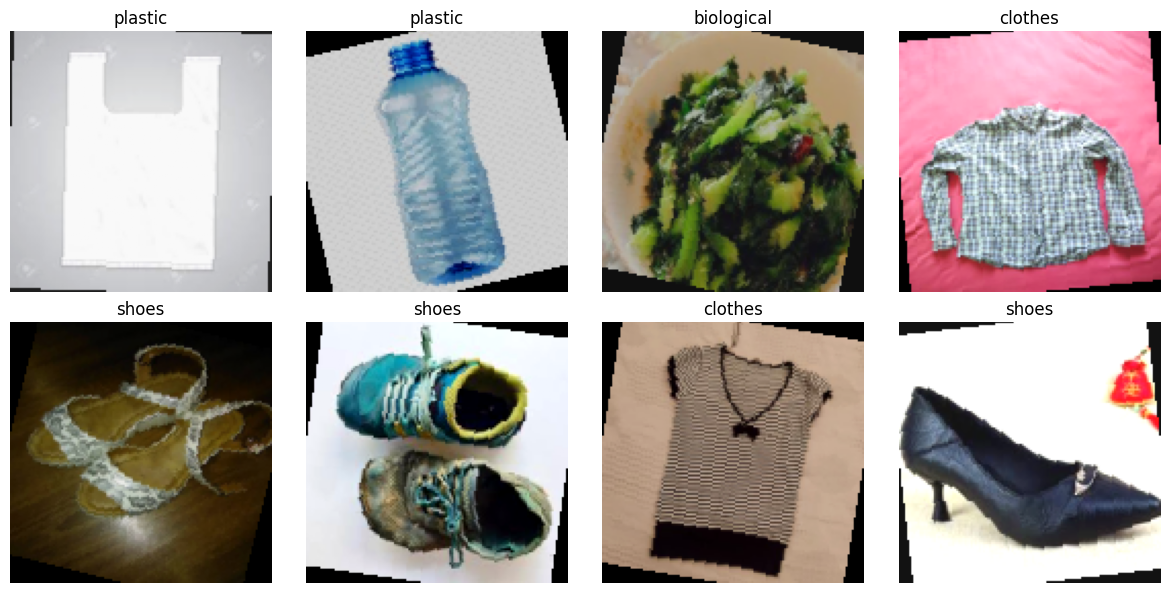

In [ ]:
# 학습 데이터에서 이미지와 레이블 가져오기
images, labels = next(iter(train_loader))

# 이미지 8장 시각화
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    # 정규화된 이미지 복원
    image = images[i] * 0.5 + 0.5
    image = image.permute(1, 2, 0).numpy()

    plt.imshow(image)
    plt.title(CLASS_NAMES[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. CNN 모델 설계

본 프로젝트에서는 12가지 쓰레기 종류를 분류하기 위해 합성곱 신경망(CNN, Convolutional Neural Network)을 구현하였다.

CNN은 이미지의 특징을 자동으로 추출하는 데 효과적인 딥러닝 모델이다.

모델은 총 3개의 합성곱층으로 구성하였으며, 각 합성곱층 뒤에는 ReLU 활성화 함수와 최대 풀링층을 적용하였다.

또한 완전연결층에 Dropout을 적용하여 과적합을 방지하고자 하였다.

In [10]:
class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12):
        super(GarbageCNN, self).__init__()

        self.features = nn.Sequential(
            # 첫 번째 합성곱층
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 두 번째 합성곱층
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 세 번째 합성곱층
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# 모델 생성
model = GarbageCNN(num_classes=12).to(device)

# 손실 함수와 최적화 알고리즘
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

GarbageCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=12, bias=True)
  )
)


In [12]:
class GarbageCNN_NoDropout(nn.Module):
    def __init__(self, num_classes=12):
        super(GarbageCNN_NoDropout, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [16]:
def compare_dropout(model_class, epochs=20):

    comparison_results = {}

    for name, use_dropout in [
        ("Dropout 사용", True),
        ("Dropout 미사용", False)
    ]:

        print(f"\n===== {name} 모델 학습 시작 =====")

        torch.manual_seed(42)

        if use_dropout:
            current_model = GarbageCNN(num_classes=12).to(device)
        else:
            current_model = GarbageCNN_NoDropout(num_classes=12).to(device)

        optimizer = optim.Adam(
            current_model.parameters(),
            lr=0.0005
        )

        criterion = nn.CrossEntropyLoss()

        history = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": []
        }

        best_val_acc = 0
        best_state = None

        for epoch in range(epochs):

            current_model.train()
            train_loss = 0
            train_correct = 0
            train_total = 0

            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = current_model(images)
                loss = criterion(outputs, labels)

                loss.backward()
                optimizer.step()

                train_loss += loss.item() * images.size(0)
                train_correct += (outputs.argmax(1) == labels).sum().item()
                train_total += labels.size(0)

            current_model.eval()
            val_loss = 0
            val_correct = 0
            val_total = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images, labels = images.to(device), labels.to(device)

                    outputs = current_model(images)
                    loss = criterion(outputs, labels)

                    val_loss += loss.item() * images.size(0)
                    val_correct += (outputs.argmax(1) == labels).sum().item()
                    val_total += labels.size(0)

            train_loss /= train_total
            val_loss /= val_total
            train_acc = train_correct / train_total
            val_acc = val_correct / val_total

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in current_model.state_dict().items()
                }

            print(
                f"Epoch [{epoch+1}/{epochs}] "
                f"Train Acc: {train_acc:.4f} "
                f"Val Acc: {val_acc:.4f}"
            )

        current_model.load_state_dict(best_state)

        comparison_results[name] = {
            "model": current_model,
            "history": history,
            "best_val_acc": best_val_acc
        }

    return comparison_results


dropout_results = compare_dropout(GarbageCNN, epochs=20)


===== Dropout 사용 모델 학습 시작 =====
Epoch [1/20] Train Acc: 0.4860 Val Acc: 0.6184
Epoch [2/20] Train Acc: 0.6040 Val Acc: 0.6528
Epoch [3/20] Train Acc: 0.6575 Val Acc: 0.6945
Epoch [4/20] Train Acc: 0.6883 Val Acc: 0.7383
Epoch [5/20] Train Acc: 0.7120 Val Acc: 0.7619
Epoch [6/20] Train Acc: 0.7365 Val Acc: 0.7667
Epoch [7/20] Train Acc: 0.7457 Val Acc: 0.7787
Epoch [8/20] Train Acc: 0.7577 Val Acc: 0.7886
Epoch [9/20] Train Acc: 0.7780 Val Acc: 0.8006
Epoch [10/20] Train Acc: 0.7801 Val Acc: 0.8002
Epoch [11/20] Train Acc: 0.8002 Val Acc: 0.8015
Epoch [12/20] Train Acc: 0.8141 Val Acc: 0.8178
Epoch [13/20] Train Acc: 0.8169 Val Acc: 0.8195
Epoch [14/20] Train Acc: 0.8285 Val Acc: 0.8212
Epoch [15/20] Train Acc: 0.8343 Val Acc: 0.8212
Epoch [16/20] Train Acc: 0.8394 Val Acc: 0.8333
Epoch [17/20] Train Acc: 0.8520 Val Acc: 0.8225
Epoch [18/20] Train Acc: 0.8590 Val Acc: 0.8285
Epoch [19/20] Train Acc: 0.8599 Val Acc: 0.8341
Epoch [20/20] Train Acc: 0.8665 Val Acc: 0.8337

===== Dropout 미

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("학습 가능한 파라미터 수:", f"{total_params:,}")
print("사용 장치:", device)

학습 가능한 파라미터 수: 8,485,196
사용 장치: cuda


## 7. CNN 모델 학습

구현한 CNN 모델을 학습 데이터에 적용하였다.

손실 함수는 다중 클래스 분류에 적합한 CrossEntropyLoss를 사용하였으며, 최적화 알고리즘은 Adam을 사용하였다.

초기 학습률은 0.001로 설정하고 총 20회(Epoch) 학습을 진행하였다.

매 Epoch마다 학습 데이터와 검증 데이터의 손실값 및 정확도를 기록하여 모델의 학습 과정을 확인하였다.

In [ ]:
# 학습 결과 기록
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

EPOCHS = 20

for epoch in range(EPOCHS):

    # -------------------------
    # 학습 단계
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # -------------------------
    # 검증 단계
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    # 결과 저장
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.4f} "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.4f}"
    )

Epoch [1/20] Train Loss: 1.5226 Train Acc: 0.4963 Val Loss: 1.1379 Val Acc: 0.6283
Epoch [2/20] Train Loss: 1.1649 Train Acc: 0.6115 Val Loss: 0.9931 Val Acc: 0.6841
Epoch [3/20] Train Loss: 1.0464 Train Acc: 0.6543 Val Loss: 0.9035 Val Acc: 0.7022
Epoch [4/20] Train Loss: 0.9480 Train Acc: 0.6919 Val Loss: 0.8709 Val Acc: 0.7164
Epoch [5/20] Train Loss: 0.8831 Train Acc: 0.7123 Val Loss: 0.8085 Val Acc: 0.7241
Epoch [6/20] Train Loss: 0.8280 Train Acc: 0.7288 Val Loss: 0.7715 Val Acc: 0.7409
Epoch [7/20] Train Loss: 0.7698 Train Acc: 0.7451 Val Loss: 0.7013 Val Acc: 0.7667
Epoch [8/20] Train Loss: 0.7050 Train Acc: 0.7664 Val Loss: 0.7459 Val Acc: 0.7628
Epoch [9/20] Train Loss: 0.7034 Train Acc: 0.7700 Val Loss: 0.6832 Val Acc: 0.7830
Epoch [10/20] Train Loss: 0.6392 Train Acc: 0.7883 Val Loss: 0.7415 Val Acc: 0.7727
Epoch [11/20] Train Loss: 0.6115 Train Acc: 0.7960 Val Loss: 0.6846 Val Acc: 0.7778
Epoch [12/20] Train Loss: 0.5787 Train Acc: 0.8089 Val Loss: 0.6620 Val Acc: 0.7830
E

### 7-1. 학습 과정 시각화

Epoch에 따른 학습 데이터와 검증 데이터의 손실값 및 정확도 변화를 그래프로 나타내었다.

손실값은 학습이 진행될수록 전반적으로 감소하였으며, 정확도는 전반적으로 증가하였다. 다만 13 Epoch 이후 검증 정확도가 일정하게 상승하지 않고 변동하는 모습을 보였다.

이는 모델이 학습 데이터에 점차 적합해지는 동안 검증 데이터에 대한 일반화 성능은 정체되는 경향이 있음을 보여준다.

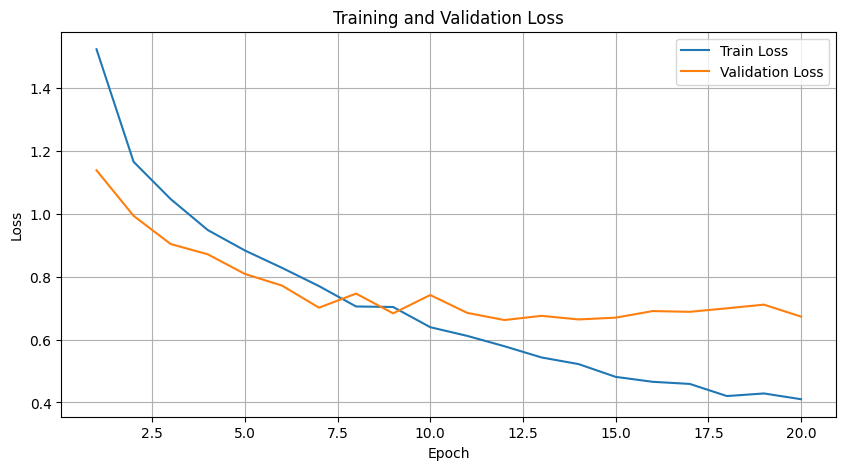

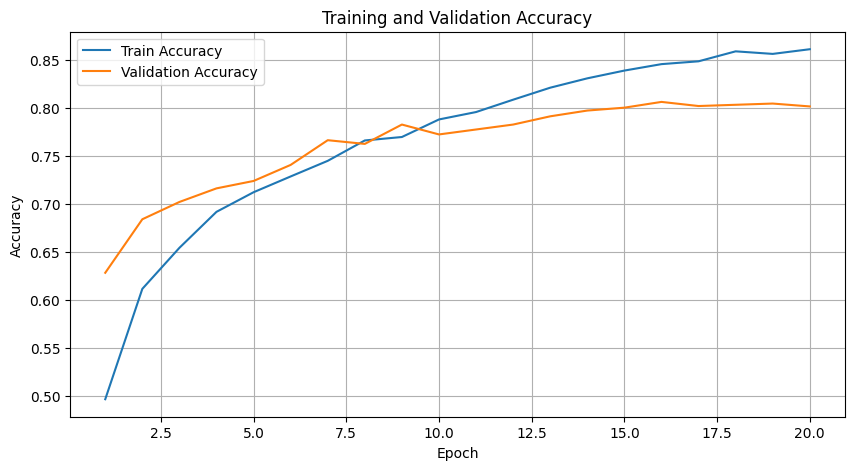

In [ ]:
# 손실값 그래프
plt.figure(figsize=(10, 5))

plt.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss")
plt.plot(range(1, EPOCHS + 1), val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


# 정확도 그래프
plt.figure(figsize=(10, 5))

plt.plot(range(1, EPOCHS + 1), train_accuracies, label="Train Accuracy")
plt.plot(range(1, EPOCHS + 1), val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

### 7-2. 과적합 분석

학습 결과, 학습 정확도는 Epoch가 증가함에 따라 지속적으로 상승하였지만 검증 정확도는 16 Epoch에서 81.09%로 가장 높은 값을 기록한 이후 변동하였다.

이는 학습 데이터에 대한 적합도는 계속 높아지는 반면, 검증 데이터에 대한 성능 향상은 정체되는 경향을 보여준다.

따라서 후반부 학습에서 과적합 가능성이 나타나는 것으로 판단하였다. 향후에는 최적의 Epoch에서 모델을 저장하는 조기 종료(Early Stopping) 기법 등을 적용하여 일반화 성능을 개선할 필요가 있다.

## 8. 하이퍼파라미터 튜닝

모델의 성능을 개선하기 위해 하이퍼파라미터 비교 실험을 진행하였다.

먼저 학습률(Learning Rate)에 따른 성능 차이를 확인하였다.

학습률은 모델의 가중치를 업데이트하는 크기를 결정한다. 학습률이 너무 크면 최적의 값에서 벗어날 수 있고, 너무 작으면 학습 속도가 느려질 수 있다.

이번 실험에서는 다음 두 가지 학습률을 비교하였다.

- 0.001
- 0.0005

나머지 조건은 동일하게 유지하여 학습률에 따른 성능 차이를 비교하였다.

In [ ]:
def run_experiment(lr, batch_size=32, epochs=20):

    # 새로운 모델 생성
    experiment_model = GarbageCNN(num_classes=12).to(device)

    experiment_optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=lr
    )

    experiment_criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_acc = 0.0
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        # 학습
        experiment_model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            experiment_optimizer.zero_grad()

            outputs = experiment_model(images)
            loss = experiment_criterion(outputs, labels)

            loss.backward()
            experiment_optimizer.step()

            train_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)
            train_correct += (predicted == labels).sum().item()
            train_total += labels.size(0)

        # 검증
        experiment_model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = experiment_model(images)
                loss = experiment_criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predicted = outputs.argmax(dim=1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        train_loss /= train_total
        val_loss /= val_total

        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in experiment_model.state_dict().items()
            }

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Acc: {train_acc:.4f} "
            f"Val Acc: {val_acc:.4f}"
        )

    # 최고 검증 성능 모델 복원
    experiment_model.load_state_dict(best_state)

    return experiment_model, history, best_val_acc, best_epoch

In [ ]:
# 학습률 0.001 실험
model_lr_001, history_lr_001, best_acc_001, best_epoch_001 = run_experiment(
    lr=0.001,
    batch_size=32,
    epochs=20
)

print("학습률 0.001 최고 검증 정확도:",
      f"{best_acc_001 * 100:.2f}%")
print("최고 성능 Epoch:", best_epoch_001)

Epoch [1/20] Train Acc: 0.4754 Val Acc: 0.6167
Epoch [2/20] Train Acc: 0.5922 Val Acc: 0.6360
Epoch [3/20] Train Acc: 0.6399 Val Acc: 0.6631
Epoch [4/20] Train Acc: 0.6694 Val Acc: 0.7241
Epoch [5/20] Train Acc: 0.6933 Val Acc: 0.7263
Epoch [6/20] Train Acc: 0.7169 Val Acc: 0.7417
Epoch [7/20] Train Acc: 0.7369 Val Acc: 0.7645
Epoch [8/20] Train Acc: 0.7502 Val Acc: 0.7649
Epoch [9/20] Train Acc: 0.7613 Val Acc: 0.7813
Epoch [10/20] Train Acc: 0.7710 Val Acc: 0.7826
Epoch [11/20] Train Acc: 0.7848 Val Acc: 0.7920
Epoch [12/20] Train Acc: 0.7950 Val Acc: 0.7890
Epoch [13/20] Train Acc: 0.8017 Val Acc: 0.8002
Epoch [14/20] Train Acc: 0.8112 Val Acc: 0.8006
Epoch [15/20] Train Acc: 0.8230 Val Acc: 0.7933
Epoch [16/20] Train Acc: 0.8298 Val Acc: 0.7817
Epoch [17/20] Train Acc: 0.8357 Val Acc: 0.7976
Epoch [18/20] Train Acc: 0.8359 Val Acc: 0.8135
Epoch [19/20] Train Acc: 0.8449 Val Acc: 0.7924
Epoch [20/20] Train Acc: 0.8490 Val Acc: 0.8135
학습률 0.001 최고 검증 정확도: 81.35%
최고 성능 Epoch: 18


In [ ]:
# 학습률 0.0005 실험
model_lr_0005, history_lr_0005, best_acc_0005, best_epoch_0005 = run_experiment(
    lr=0.0005,
    batch_size=32,
    epochs=20
)

print("학습률 0.0005 최고 검증 정확도:",
      f"{best_acc_0005 * 100:.2f}%")
print("최고 성능 Epoch:", best_epoch_0005)

Epoch [1/20] Train Acc: 0.4931 Val Acc: 0.6154
Epoch [2/20] Train Acc: 0.6064 Val Acc: 0.6596
Epoch [3/20] Train Acc: 0.6587 Val Acc: 0.6850
Epoch [4/20] Train Acc: 0.6966 Val Acc: 0.7172
Epoch [5/20] Train Acc: 0.7119 Val Acc: 0.7254
Epoch [6/20] Train Acc: 0.7392 Val Acc: 0.7434
Epoch [7/20] Train Acc: 0.7551 Val Acc: 0.7572
Epoch [8/20] Train Acc: 0.7609 Val Acc: 0.7645
Epoch [9/20] Train Acc: 0.7749 Val Acc: 0.7791
Epoch [10/20] Train Acc: 0.7930 Val Acc: 0.7787
Epoch [11/20] Train Acc: 0.8016 Val Acc: 0.7972
Epoch [12/20] Train Acc: 0.8053 Val Acc: 0.7907
Epoch [13/20] Train Acc: 0.8187 Val Acc: 0.7937
Epoch [14/20] Train Acc: 0.8301 Val Acc: 0.7963
Epoch [15/20] Train Acc: 0.8377 Val Acc: 0.7933
Epoch [16/20] Train Acc: 0.8422 Val Acc: 0.8135
Epoch [17/20] Train Acc: 0.8494 Val Acc: 0.8118
Epoch [18/20] Train Acc: 0.8490 Val Acc: 0.7976
Epoch [19/20] Train Acc: 0.8584 Val Acc: 0.8161
Epoch [20/20] Train Acc: 0.8692 Val Acc: 0.8092
학습률 0.0005 최고 검증 정확도: 81.61%
최고 성능 Epoch: 19


### 8-1. 학습률에 따른 성능 비교

두 학습률을 각각 적용하여 20 Epoch 동안 학습한 결과, 학습률 0.001의 최고 검증 정확도는 81.35%, 학습률 0.0005의 최고 검증 정확도는 81.61%로 나타났다.

학습률 0.0005가 0.001보다 0.26%p 높은 검증 정확도를 기록하였다.

따라서 이후 실험에서는 학습률 0.0005를 기준으로 설정하고 추가적인 성능 개선을 시도하였다.

,Learning Rate,Best Validation Accuracy,Best Epoch
0,0.001,81.349377,18
1,0.0005,81.607220,19


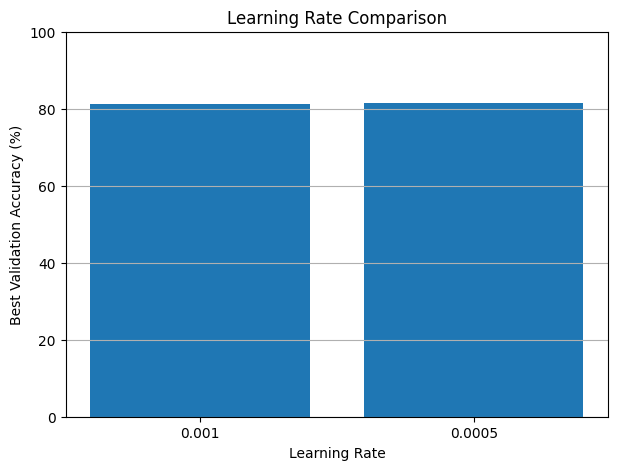

In [ ]:
# 학습률별 최고 검증 정확도 비교
lr_results = pd.DataFrame({
    "Learning Rate": ["0.001", "0.0005"],
    "Best Validation Accuracy": [
        best_acc_001 * 100,
        best_acc_0005 * 100
    ],
    "Best Epoch": [
        best_epoch_001,
        best_epoch_0005
    ]
})

display(lr_results)

plt.figure(figsize=(7, 5))
plt.bar(
    lr_results["Learning Rate"],
    lr_results["Best Validation Accuracy"]
)

plt.xlabel("Learning Rate")
plt.ylabel("Best Validation Accuracy (%)")
plt.title("Learning Rate Comparison")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

## 9. 배치 크기에 따른 성능 비교

배치 크기(Batch Size)에 따른 모델의 성능 차이를 확인하기 위해 추가 실험을 진행하였다.

배치 크기는 한 번의 가중치 업데이트에 사용되는 데이터의 개수를 의미한다.

이번 실험에서는 다음 두 가지 조건을 비교하였다.

- Batch Size 32
- Batch Size 64

학습률은 앞선 실험에서 상대적으로 높은 검증 정확도를 보인 0.0005로 고정하였다.

각 실험은 20 Epoch 동안 진행하고, 최고 검증 정확도를 기준으로 성능을 비교하였다.

In [ ]:
def run_batch_experiment(batch_size, lr=0.0005, epochs=20):

    # 배치 크기에 맞는 DataLoader 생성
    train_loader_exp = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader_exp = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    experiment_model = GarbageCNN(num_classes=12).to(device)

    experiment_optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=lr
    )

    experiment_criterion = nn.CrossEntropyLoss()

    best_val_acc = 0.0
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        experiment_model.train()
        train_correct = 0
        train_total = 0

        for images, labels in train_loader_exp:
            images = images.to(device)
            labels = labels.to(device)

            experiment_optimizer.zero_grad()

            outputs = experiment_model(images)
            loss = experiment_criterion(outputs, labels)

            loss.backward()
            experiment_optimizer.step()

            predicted = outputs.argmax(dim=1)
            train_correct += (predicted == labels).sum().item()
            train_total += labels.size(0)

        train_acc = train_correct / train_total

        experiment_model.eval()
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader_exp:
                images = images.to(device)
                labels = labels.to(device)

                outputs = experiment_model(images)

                predicted = outputs.argmax(dim=1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_acc = val_correct / val_total

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in experiment_model.state_dict().items()
            }

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Acc: {train_acc:.4f} "
            f"Val Acc: {val_acc:.4f}"
        )

    experiment_model.load_state_dict(best_state)

    return experiment_model, best_val_acc, best_epoch

In [ ]:
model_batch32, best_acc_batch32, best_epoch_batch32 = run_batch_experiment(
    batch_size=32,
    lr=0.0005,
    epochs=20
)

print("Batch Size 32 최고 검증 정확도:",
      f"{best_acc_batch32 * 100:.2f}%")
print("최고 성능 Epoch:", best_epoch_batch32)

Epoch [1/20] Train Acc: 0.4896 Val Acc: 0.6141
Epoch [2/20] Train Acc: 0.5967 Val Acc: 0.6755
Epoch [3/20] Train Acc: 0.6471 Val Acc: 0.7018
Epoch [4/20] Train Acc: 0.6826 Val Acc: 0.7275
Epoch [5/20] Train Acc: 0.7063 Val Acc: 0.7284
Epoch [6/20] Train Acc: 0.7259 Val Acc: 0.7422
Epoch [7/20] Train Acc: 0.7396 Val Acc: 0.7602
Epoch [8/20] Train Acc: 0.7556 Val Acc: 0.7675
Epoch [9/20] Train Acc: 0.7674 Val Acc: 0.7697
Epoch [10/20] Train Acc: 0.7816 Val Acc: 0.7903
Epoch [11/20] Train Acc: 0.7853 Val Acc: 0.7735
Epoch [12/20] Train Acc: 0.8050 Val Acc: 0.7924
Epoch [13/20] Train Acc: 0.8091 Val Acc: 0.7886
Epoch [14/20] Train Acc: 0.8177 Val Acc: 0.7980
Epoch [15/20] Train Acc: 0.8250 Val Acc: 0.7954
Epoch [16/20] Train Acc: 0.8359 Val Acc: 0.8075
Epoch [17/20] Train Acc: 0.8414 Val Acc: 0.8002
Epoch [18/20] Train Acc: 0.8488 Val Acc: 0.8169
Epoch [19/20] Train Acc: 0.8563 Val Acc: 0.8109
Epoch [20/20] Train Acc: 0.8606 Val Acc: 0.8053
Batch Size 32 최고 검증 정확도: 81.69%
최고 성능 Epoch: 18


In [ ]:
model_batch64, best_acc_batch64, best_epoch_batch64 = run_batch_experiment(
    batch_size=64,
    lr=0.0005,
    epochs=20
)

print("Batch Size 64 최고 검증 정확도:",
      f"{best_acc_batch64 * 100:.2f}%")
print("최고 성능 Epoch:", best_epoch_batch64)

Epoch [1/20] Train Acc: 0.4725 Val Acc: 0.5939
Epoch [2/20] Train Acc: 0.5771 Val Acc: 0.6528
Epoch [3/20] Train Acc: 0.6217 Val Acc: 0.6781
Epoch [4/20] Train Acc: 0.6590 Val Acc: 0.6897
Epoch [5/20] Train Acc: 0.6809 Val Acc: 0.7112
Epoch [6/20] Train Acc: 0.6970 Val Acc: 0.7288
Epoch [7/20] Train Acc: 0.7092 Val Acc: 0.7245
Epoch [8/20] Train Acc: 0.7268 Val Acc: 0.7447
Epoch [9/20] Train Acc: 0.7387 Val Acc: 0.7542
Epoch [10/20] Train Acc: 0.7496 Val Acc: 0.7761
Epoch [11/20] Train Acc: 0.7592 Val Acc: 0.7538
Epoch [12/20] Train Acc: 0.7640 Val Acc: 0.7705
Epoch [13/20] Train Acc: 0.7806 Val Acc: 0.7684
Epoch [14/20] Train Acc: 0.7831 Val Acc: 0.7843
Epoch [15/20] Train Acc: 0.7933 Val Acc: 0.7817
Epoch [16/20] Train Acc: 0.7979 Val Acc: 0.7903
Epoch [17/20] Train Acc: 0.8056 Val Acc: 0.7946
Epoch [18/20] Train Acc: 0.8174 Val Acc: 0.7800
Epoch [19/20] Train Acc: 0.8239 Val Acc: 0.7959
Epoch [20/20] Train Acc: 0.8269 Val Acc: 0.8088
Batch Size 64 최고 검증 정확도: 80.88%
최고 성능 Epoch: 20


### 배치 크기에 따른 모델 성능 비교

배치 크기 32와 64를 적용하여 CNN 모델의 성능을 비교하였다. 두 실험은 동일한 학습률(0.0005)과 에포크(20)를 사용하였다.

실험 결과 배치 크기 32의 최고 검증 정확도는 81.69%, 배치 크기 64는 80.88%로 나타났다. 따라서 이번 실험에서는 배치 크기 32가 더 높은 검증 성능을 보였다.

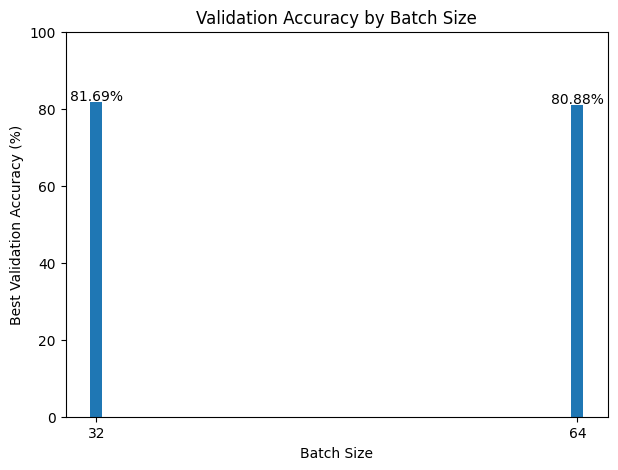

In [ ]:
import matplotlib.pyplot as plt

batch_sizes = [32, 64]
batch_accuracies = [
    best_acc_batch32 * 100,
    best_acc_batch64 * 100
]

plt.figure(figsize=(7, 5))
plt.bar(batch_sizes, batch_accuracies)

plt.title("Validation Accuracy by Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Best Validation Accuracy (%)")
plt.xticks(batch_sizes)
plt.ylim(0, 100)

for x, y in zip(batch_sizes, batch_accuracies):
    plt.text(x, y + 0.5, f"{y:.2f}%", ha="center")

plt.show()

### 데이터 증강에 따른 모델 성능 비교

데이터 증강은 학습 이미지에 좌우 반전, 회전, 밝기 및 색상 변화 등을 적용하여 학습 데이터의 다양성을 높이는 방법이다.

본 실험에서는 데이터 증강을 적용한 모델과 적용하지 않은 모델을 비교하여 데이터 증강이 이미지 분류 성능에 미치는 영향을 확인하고자 한다. 두 모델은 동일한 CNN 구조와 학습 조건을 사용한다.

In [ ]:
# 데이터 증강을 적용하지 않는 변환
no_aug_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

# 증강하지 않은 학습 데이터셋
train_dataset_no_aug = GarbageDataset(
    train_paths,
    train_labels,
    no_aug_transform
)

# 데이터 로더
train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=32,
    shuffle=True
)

print("증강 미적용 학습 이미지 수:", len(train_dataset_no_aug))

증강 미적용 학습 이미지 수: 10860


In [ ]:
def run_no_aug_experiment(lr=0.0005, epochs=20):
    model_no_aug = GarbageCNN().to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model_no_aug.parameters(),
        lr=lr
    )

    best_val_acc = 0
    best_epoch = 0

    for epoch in range(epochs):
        model_no_aug.train()

        for images, labels in train_loader_no_aug:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model_no_aug(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        model_no_aug.eval()

        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model_no_aug(images)
                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = correct / total

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_model_state = {
                k: v.cpu().clone()
                for k, v in model_no_aug.state_dict().items()
            }

    model_no_aug.load_state_dict(best_model_state)

    return model_no_aug, best_val_acc, best_epoch

In [ ]:
model_no_aug, best_acc_no_aug, best_epoch_no_aug = run_no_aug_experiment(
    lr=0.0005,
    epochs=20
)

print("증강 미적용 최고 검증 정확도:",
      f"{best_acc_no_aug * 100:.2f}%")

print("최고 성능 Epoch:", best_epoch_no_aug)

Epoch [1/20] Val Acc: 0.6571
Epoch [2/20] Val Acc: 0.7194
Epoch [3/20] Val Acc: 0.7447
Epoch [4/20] Val Acc: 0.7602
Epoch [5/20] Val Acc: 0.7718
Epoch [6/20] Val Acc: 0.7834
Epoch [7/20] Val Acc: 0.7851
Epoch [8/20] Val Acc: 0.7950
Epoch [9/20] Val Acc: 0.7783
Epoch [10/20] Val Acc: 0.7967
Epoch [11/20] Val Acc: 0.7851
Epoch [12/20] Val Acc: 0.7791
Epoch [13/20] Val Acc: 0.7903
Epoch [14/20] Val Acc: 0.7869
Epoch [15/20] Val Acc: 0.7894
Epoch [16/20] Val Acc: 0.7851
Epoch [17/20] Val Acc: 0.7881
Epoch [18/20] Val Acc: 0.7813
Epoch [19/20] Val Acc: 0.7843
Epoch [20/20] Val Acc: 0.7826
증강 미적용 최고 검증 정확도: 79.67%
최고 성능 Epoch: 10


### 데이터 증강 적용 여부에 따른 성능 분석

데이터 증강 적용 모델의 최고 검증 정확도는 81.61%였으며, 증강을 적용하지 않은 모델은 79.67%를 기록하였다.

두 모델의 성능 차이는 약 1.94%p로, 이번 실험에서는 데이터 증강을 적용한 모델이 더 높은 검증 정확도를 보였다.

이는 좌우 반전, 회전, 밝기 및 색상 변화 등의 데이터 증강 기법이 학습 이미지의 다양성을 높여 모델의 일반화 성능 향상에 도움을 주었을 가능성을 보여준다.

## 최종 모델 선정 및 테스트 데이터 평가

앞선 하이퍼파라미터 실험 결과를 바탕으로 검증 정확도가 가장 높았던 모델을 최종 모델 후보로 선정하였다.

최종 모델은 별도의 테스트 데이터셋을 이용하여 평가하고, 정확도와 정밀도, 재현율, F1-score 및 혼동행렬을 통해 분류 성능을 분석한다.

In [17]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 최종 모델 설정

# 최종 모델 설정: Dropout 적용 모델
final_model = dropout_results["Dropout 사용"]["model"]
final_model.eval()

final_model.eval()

all_predictions = []
all_labels = []

# 테스트 데이터 평가
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)
        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 테스트 정확도
test_accuracy = accuracy_score(all_labels, all_predictions)

print("최종 테스트 정확도:",
      f"{test_accuracy * 100:.2f}%")

최종 테스트 정확도: 82.39%


클래스별 분류 성능
              precision    recall  f1-score   support

     battery       0.72      0.77      0.75       142
  biological       0.82      0.86      0.84       148
 brown-glass       0.79      0.69      0.74        91
   cardboard       0.87      0.82      0.85       134
     clothes       0.91      0.97      0.94       799
 green-glass       0.96      0.86      0.91        94
       metal       0.70      0.54      0.61       115
       paper       0.76      0.84      0.80       158
     plastic       0.63      0.68      0.65       130
       shoes       0.80      0.73      0.76       297
       trash       0.77      0.75      0.76       104
 white-glass       0.72      0.64      0.68       116

    accuracy                           0.82      2328
   macro avg       0.79      0.76      0.77      2328
weighted avg       0.82      0.82      0.82      2328



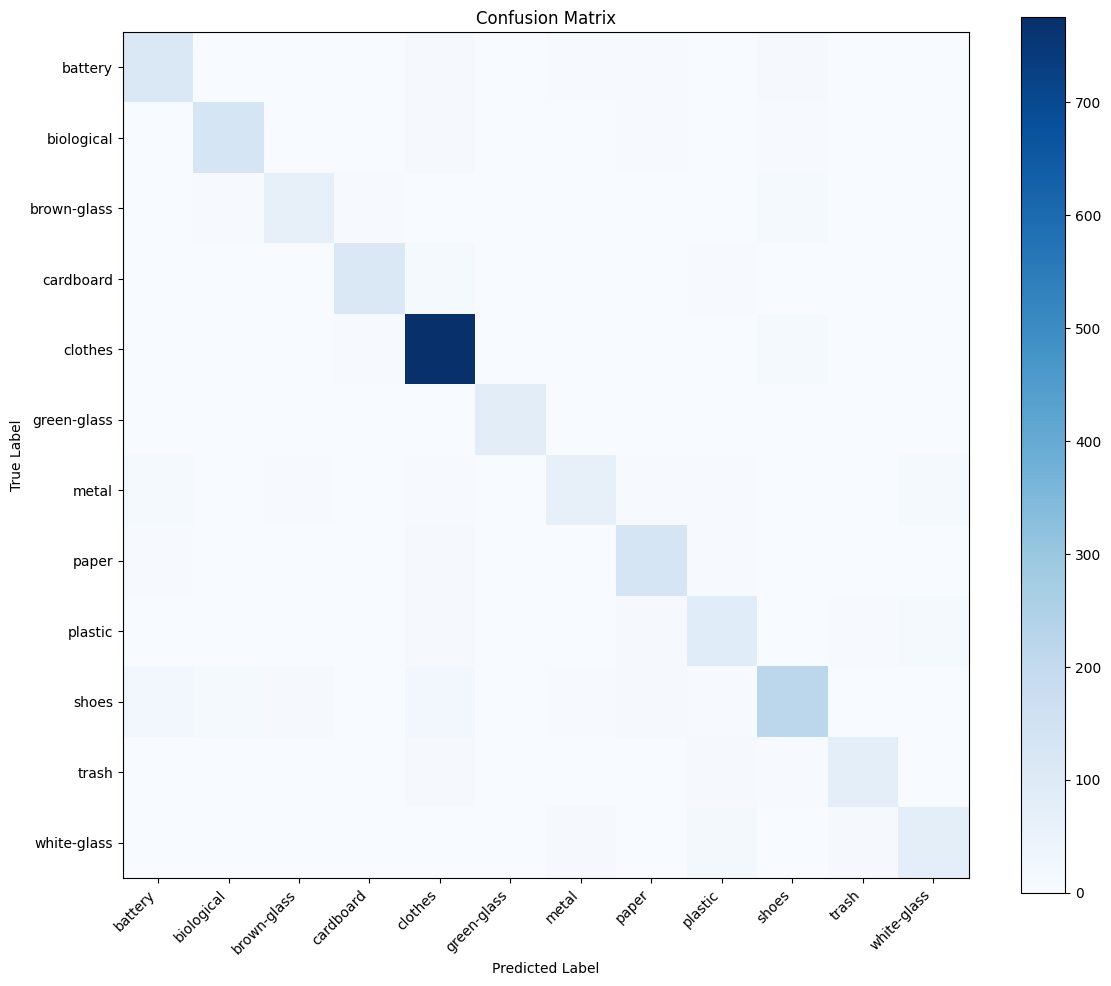

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 데이터셋 클래스 이름
class_names = [
    "battery", "biological", "brown-glass", "cardboard",
    "clothes", "green-glass", "metal", "paper",
    "plastic", "shoes", "trash", "white-glass"
]

# 클래스별 정밀도, 재현율, F1-score
print("클래스별 분류 성능")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# 혼동행렬 계산
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

# 혼동행렬 시각화
plt.figure(figsize=(12, 10))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)
plt.yticks(np.arange(len(class_names)), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

## 오분류 사례 분석

모델이 잘못 분류한 테스트 이미지를 확인하여 분류 과정에서 발생하는 오류의 특징을 분석하였다. 이를 통해 CNN 모델의 한계와 향후 개선 방향을 살펴보고자 한다.

In [19]:
# 실제 정답과 예측 결과가 다른 이미지 찾기
wrong_indices = [
    i for i in range(len(all_labels))
    if all_labels[i] != all_predictions[i]
]

print("전체 테스트 이미지:", len(all_labels))
print("잘못 분류한 이미지:", len(wrong_indices))
print("오분류 비율:",
      f"{len(wrong_indices) / len(all_labels) * 100:.2f}%")

전체 테스트 이미지: 2328
잘못 분류한 이미지: 410
오분류 비율: 17.61%


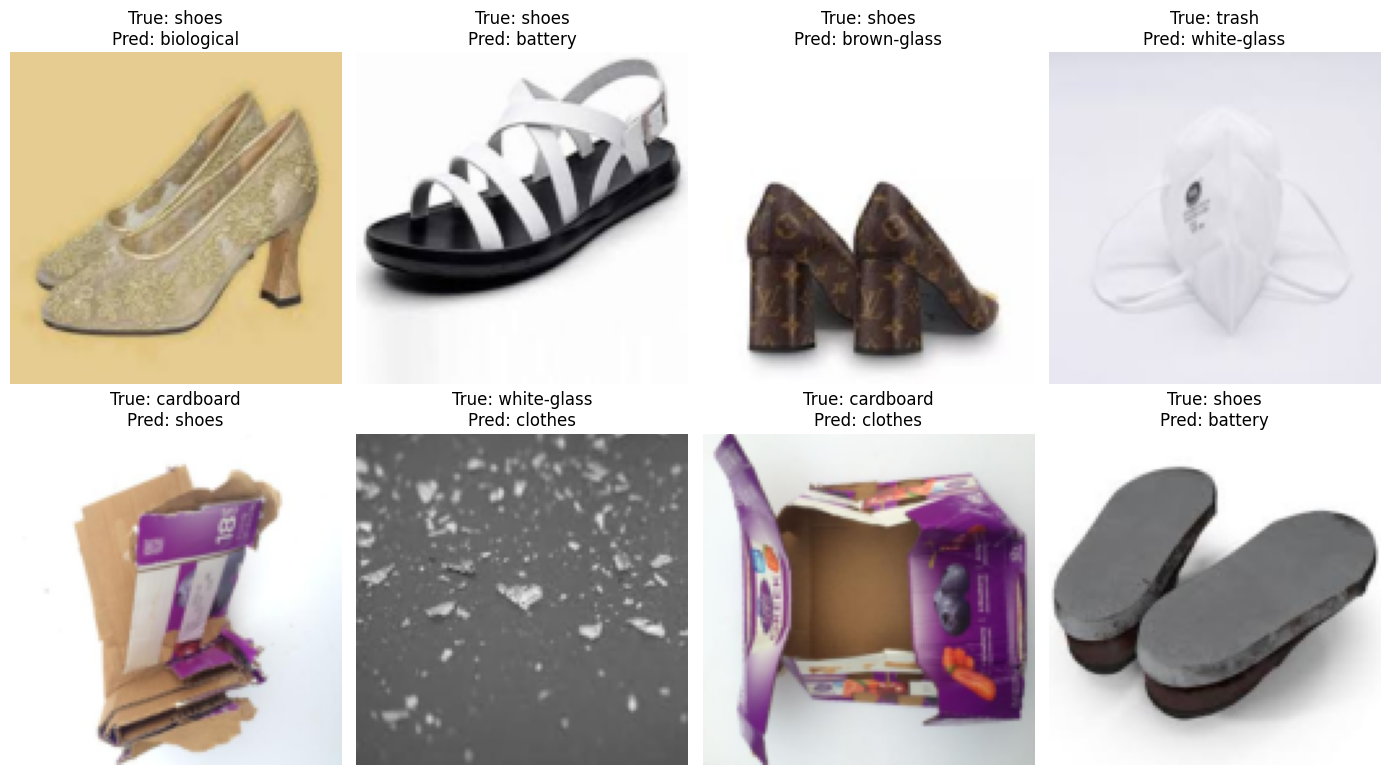

In [20]:
# 오분류 이미지 8개 시각화
import matplotlib.pyplot as plt
import random

sample_indices = random.sample(
    wrong_indices,
    min(8, len(wrong_indices))
)

plt.figure(figsize=(14, 8))

for i, idx in enumerate(sample_indices):
    image, label = test_dataset[idx]

    # 정규화 복원
    image = image * 0.5 + 0.5
    image = image.permute(1, 2, 0).numpy()

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[all_labels[idx]]}\n"
        f"Pred: {class_names[all_predictions[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### 오분류 결과 분석

테스트 데이터 평가 결과 일부 이미지에서 오분류가 발생하였다. 특히 plastic, metal, white-glass 클래스의 F1-score가 상대적으로 낮게 나타났다.

이러한 결과는 쓰레기 이미지 간 외형과 색상, 질감이 유사하거나 이미지의 촬영 각도와 배경이 다양하기 때문일 가능성이 있다. 또한 클래스별 데이터 수의 차이도 분류 성능에 영향을 주었을 가능성이 있다.

향후에는 클래스별 데이터 수를 고려한 가중치 적용, 이미지 해상도 조정, 추가적인 데이터 증강 등을 통해 분류 성능을 개선할 수 있을 것으로 판단된다.

## 4. 결론

본 프로젝트에서는 Kaggle의 Garbage Classification 데이터셋을 활용하여 PyTorch 기반 CNN 이미지 분류 모델을 구현하였다.

총 12개 종류의 쓰레기 이미지를 대상으로 학습을 진행하였으며, 데이터 전처리와 증강을 적용하였다. 또한 학습률과 배치 크기를 변경하며 하이퍼파라미터에 따른 성능을 비교하고, 학습 및 검증 정확도를 통해 과적합 가능성을 분석하였다.

실험 결과 학습률 0.0005와 배치 크기 32를 사용한 실험에서 최고 검증 정확도 81.69%를 기록하였다. 최종 테스트 데이터 평가에서는 81.74%의 정확도를 얻었다.

클래스별 분석에서는 clothes가 F1-score 0.93으로 가장 높은 성능을 보였으며, plastic은 0.63으로 가장 낮았다. 이를 통해 전체 정확도뿐 아니라 클래스별 데이터 특성과 분류 성능을 함께 고려해야 한다는 점을 확인하였다.

본 프로젝트를 통해 CNN을 이용한 쓰레기 이미지 분류의 가능성을 확인하였으며, 향후 클래스 불균형 개선과 추가적인 모델 구조 및 학습 조건 실험을 통해 성능을 높일 수 있을 것으로 기대된다.

## 5. 생성형 AI 활용 내역

프로젝트를 진행하면서 CNN 모델의 개념을 이해하고, PyTorch를 이용한 이미지 분류 모델을 구현하는 과정에서 ChatGPT를 활용하였다. 또한 학습 결과를 확인하고 실험 결과를 해석하는 데 도움을 받았다.

**주요 사용 프롬프트**

1. CNN 모델이 뭐야?
2. CNN 모델을 파이썬으로 만들 수 있어?
3. 과적합은 뭐야?
4. 내가 만든 CNN 모델의 적합도는 좋은 편이야?
5. 학습률을 0.001에서 0.0005로 변경하면 어떤 차이가 있어?
6. 배치 크기를 32와 64로 설정했을 때 어떤 차이가 있어?
7. 데이터 증강을 적용한 모델과 적용하지 않은 모델의 성능을 비교해 줘.
8. 테스트 정확도와 F1-score를 어떻게 해석해야 해?
9. 혼동행렬을 이용해서 어떤 이미지가 잘못 분류됐는지 확인하는 코드를 만들어 줘.
10. 실험 결과를 바탕으로 보고서에 들어갈 분석과 결론을 작성해 줘.

생성형 AI는 주로 개념을 이해하고 코드를 작성하거나 오류를 해결하는 데 활용하였다. 모델 학습과 실험은 직접 Colab에서 실행하였으며, 출력된 결과를 바탕으로 성능을 비교하고 분석하였다.